In [6]:
# data_preparation.py
import os
import numpy as np
import cv2
from sklearn.model_selection import train_test_split

def prepare_data(data_dir, categories, img_size):
    """Load and prepare image data from specified directories."""
    data = []
    labels = []
    class_counts = {}
    
    for category in categories:
        path = os.path.join(data_dir, category)
        label = categories.index(category)
        
        files = os.listdir(path)
        class_counts[category] = len(files)
        
        for img_name in files:
            img_path = os.path.join(path, img_name)
            img = cv2.imread(img_path)
            
            if img is not None:
                img = cv2.resize(img, (img_size, img_size))
                img = img / 255.0  # Normalize
                data.append(img)
                labels.append(label)
    
    # Print class distribution
    print("Class distribution:")
    for category, count in class_counts.items():
        print(f"{category}: {count} images")
    
    # Convert to numpy arrays
    data = np.array(data, dtype="float32")
    labels = np.array(labels, dtype="int")
    
    return data, labels, class_counts

def split_data(data, labels, test_size=0.2, random_state=42):
    """Split the dataset into training and validation sets."""
    X_train, X_val, y_train, y_val = train_test_split(
        data, labels, test_size=test_size, random_state=random_state, stratify=labels
    )
    
    print(f"Training Data Shape: {X_train.shape}, Validation Data Shape: {X_val.shape}")
    print(f"Training Labels Distribution: {np.bincount(y_train)}")
    print(f"Validation Labels Distribution: {np.bincount(y_val)}")
    
    return X_train, X_val, y_train, y_val

def calculate_class_weights(y_train):
    """Calculate class weights to handle class imbalance."""
    total_samples = len(y_train)
    n_samples_class0 = np.sum(y_train == 0)
    n_samples_class1 = np.sum(y_train == 1)
    
    class_weight = {
        0: total_samples / (2 * n_samples_class0) if n_samples_class0 > 0 else 1.0,
        1: total_samples / (2 * n_samples_class1) if n_samples_class1 > 0 else 1.0
    }
    
    print(f"Class weights: {class_weight}")
    return class_weight

In [5]:
# model_architecture.py
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def create_model(img_size):
    """Create and compile the CNN model for drowsiness detection."""
    model = keras.Sequential([
        # First Convolutional Block
        layers.Conv2D(32, (3,3), activation="relu", input_shape=(img_size, img_size, 3)),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),
        
        # Second Convolutional Block
        layers.Conv2D(64, (3,3), activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),
        
        # Third Convolutional Block
        layers.Conv2D(128, (3,3), activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),
        
        # Flatten and Dense Layers
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        
        # Output Layer
        layers.Dense(1, activation="sigmoid")
    ])
    
    # Compile the model
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0001),
        loss="binary_crossentropy",
        metrics=[
            "accuracy", 
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall')
        ]
    )
    
    return model

def get_callbacks():
    """Define callbacks for model training."""
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=3,
            min_lr=0.00001
        )
    ]
    return callbacks

In [4]:
# training_evaluation.py

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def setup_data_generators():
    """Set up data generators for training and validation."""
    # Training data generator with augmentation
    train_datagen = ImageDataGenerator(
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True,
        fill_mode="nearest"
    )
    
    # Validation data generator (no augmentation)
    val_datagen = ImageDataGenerator()
    
    return train_datagen, val_datagen

def train_model(model, X_train, y_train, X_val, y_val, 
                train_datagen, val_datagen, class_weight, callbacks, batch_size=32, epochs=10):
    """Train the model and return training history."""
    history = model.fit(
        train_datagen.flow(X_train, y_train, batch_size=batch_size),
        validation_data=val_datagen.flow(X_val, y_val, batch_size=batch_size, shuffle=False),
        epochs=epochs,
        verbose=1,
        class_weight=class_weight,
        callbacks=callbacks
    )
    
    return history

def evaluate_model(model, X_val, y_val, categories):
    """Evaluate the model and display metrics."""
    # Generate predictions
    y_pred_prob = model.predict(X_val)
    y_pred = (y_pred_prob > 0.5).astype(int).reshape(-1)
    
    # Print classification report
    print("\nClassification Report:")
    print(classification_report(y_val, y_pred, target_names=categories))
    
    # Display confusion matrix
    cm = confusion_matrix(y_val, y_pred)
    print("\nConfusion Matrix:")
    print(cm)
    
    return y_pred, cm

def plot_confusion_matrix(cm, categories):
    """Plot and save the confusion matrix."""
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(len(categories))
    plt.xticks(tick_marks, categories, rotation=45)
    plt.yticks(tick_marks, categories)
    
    # Add text annotations
    thresh = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, format(cm[i, j], 'd'),
                    horizontalalignment="center",
                    color="white" if cm[i, j] > thresh else "black")
    
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.savefig('confusion_matrix.png')
    plt.show()

def plot_training_history(history):
    """Plot and save the training history."""
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    
    plt.tight_layout()
    plt.savefig('training_history.png')
    plt.show()

def visualize_predictions(X_val, y_val, y_pred, categories, num_samples=5):
    """Visualize sample predictions."""
    indices = np.random.choice(range(len(y_val)), num_samples, replace=False)
    
    plt.figure(figsize=(15, 3*num_samples))
    for i, idx in enumerate(indices):
        plt.subplot(num_samples, 1, i+1)
        plt.imshow(X_val[idx])
        true_label = categories[y_val[idx]]
        pred_label = categories[y_pred[idx]]
        color = "green" if true_label == pred_label else "red"
        plt.title(f"True: {true_label}, Predicted: {pred_label}", color=color)
        plt.axis('off')
    
    plt.tight_layout()
    plt.savefig('prediction_samples.png')
    plt.show()

In [3]:
# prediction.py
import cv2
import numpy as np

def predict_image(image_path, model, categories, img_size):
    """
    Predict drowsiness for a single image.
    
    Args:
        image_path: Path to the image file
        model: Trained model
        categories: List of class categories
        img_size: Image size for resizing
        
    Returns:
        Dictionary with predicted class and confidence
    """
    # Load and preprocess image
    img = cv2.imread(image_path)
    if img is None:
        return {"error": f"Could not load image from {image_path}"}
    
    img = cv2.resize(img, (img_size, img_size))
    img = img / 255.0
    img = np.expand_dims(img, axis=0)  # Add batch dimension
    
    # Predict
    prediction = model.predict(img)[0][0]
    predicted_class = int(prediction > 0.5)
    
    return {
        'class': categories[predicted_class],
        'confidence': float(prediction) if predicted_class == 1 else 1 - float(prediction)
    }

def predict_from_webcam(model, categories, img_size, display_time=10):
    """
    Capture webcam feed and predict drowsiness in real-time.
    
    Args:
        model: Trained model
        categories: List of class categories
        img_size: Image size for resizing
        display_time: Time in seconds to display the webcam feed
        
    Note: Press 'q' to quit early
    """
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("Error: Could not open webcam.")
        return
    
    print(f"Starting webcam prediction. Press 'q' to quit.")
    
    while True:
        ret, frame = cap.read()
        if not ret:
            print("Error: Could not read frame.")
            break
        
        # Preprocess frame
        processed_frame = cv2.resize(frame, (img_size, img_size))
        processed_frame = processed_frame / 255.0
        processed_frame = np.expand_dims(processed_frame, axis=0)
        
        # Make prediction
        prediction = model.predict(processed_frame)[0][0]
        predicted_class = int(prediction > 0.5)
        confidence = float(prediction) if predicted_class == 1 else 1 - float(prediction)
        
        # Display result on frame
        result_text = f"{categories[predicted_class]}: {confidence*100:.2f}%"
        color = (0, 255, 0) if predicted_class == 1 else (0, 0, 255)  # Green for Non-Drowsy, Red for Drowsy
        cv2.putText(frame, result_text, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)
        
        # Display the frame
        cv2.imshow('Drowsiness Detection', frame)
        
        # Break loop on 'q' key press
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break
    
    # Release resources
    cap.release()
    cv2.destroyAllWindows()

GPU is available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
=== Starting Training Mode ===
Class distribution:
Drowsy: 22348 images
Non Drowsy: 19445 images
Training Data Shape: (33434, 128, 128, 3), Validation Data Shape: (8359, 128, 128, 3)
Training Labels Distribution: [17878 15556]
Validation Labels Distribution: [4470 3889]
Class weights: {0: 0.935059850095089, 1: 1.07463358189766}
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 126, 126, 32)      896       
                                                                 
 batch_normalization (BatchN  (None, 126, 126, 32)     128       
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 63, 63, 32)       0         
 )                                   

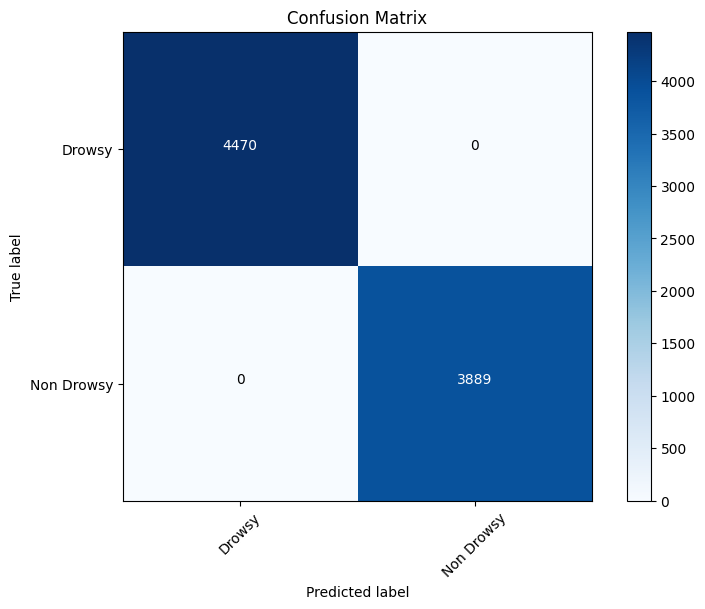

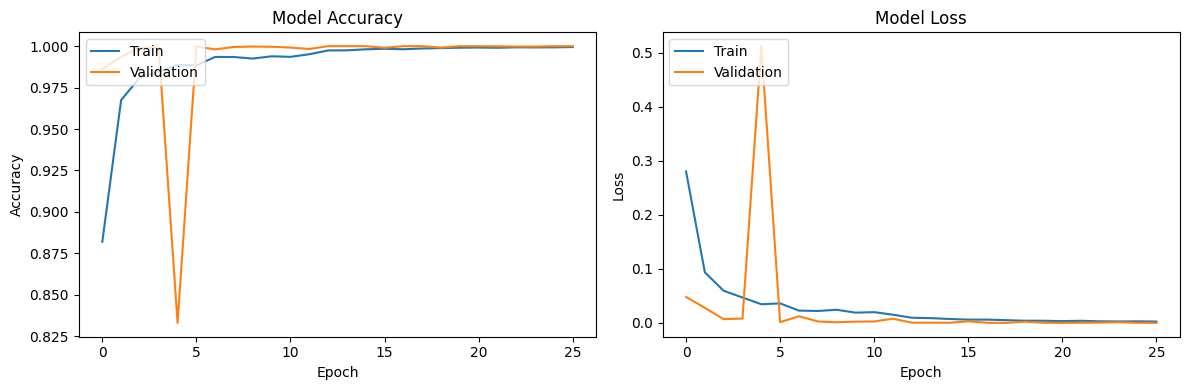

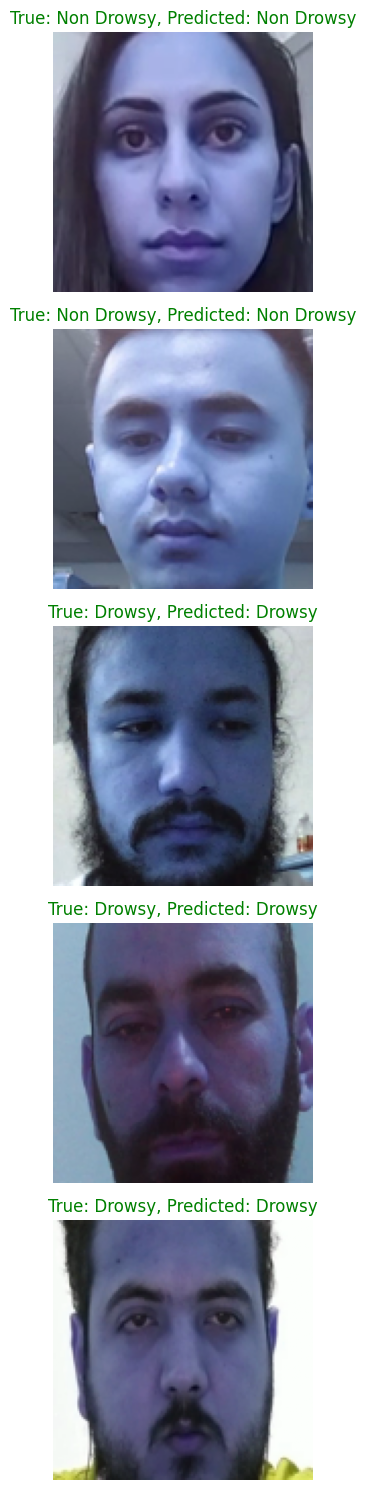

In [7]:
# main.py
import os
import argparse
import tensorflow as tf

# Import our modules
# from data_preparation import prepare_data, split_data, calculate_class_weights
# from model_architecture import create_model, get_callbacks
# from training_evaluation import (setup_data_generators, train_model, evaluate_model, 
#                                 plot_confusion_matrix, plot_training_history, 
#                                 visualize_predictions)
# from prediction import predict_image, predict_from_webcam

def main():
    parser = argparse.ArgumentParser(description='Drowsiness Detection System')
    parser.add_argument('--data_dir', default='./Dataset', help='Path to the dataset directory')
    parser.add_argument('--img_size', type=int, default=128, help='Image size for processing')
    parser.add_argument('--batch_size', type=int, default=32, help='Batch size for training')
    parser.add_argument('--epochs', type=int, default=30, help='Number of training epochs')
    parser.add_argument('--model_path', default='drowsiness_model.h5', help='Path to save/load model')
    parser.add_argument('--mode', choices=['train', 'evaluate', 'predict', 'webcam'], 
                        default='train', help='Mode of operation')
    parser.add_argument('--image_path', help='Path to image for prediction (only for predict mode)')
    
    args, unknown = parser.parse_known_args()
    if unknown:
        print(f"Warning: Ignoring unrecognized arguments: {unknown}")
    
    # Define categories
    categories = ["Drowsy", "Non Drowsy"]
    
    # Check for GPU
    physical_devices = tf.config.list_physical_devices('GPU')
    if physical_devices:
        print(f"GPU is available: {physical_devices}")
        # Set memory growth to avoid filling whole GPU memory
        for device in physical_devices:
            tf.config.experimental.set_memory_growth(device, True)
    else:
        print("No GPU found, using CPU.")
    
    if args.mode == 'train':
        print("=== Starting Training Mode ===")
        
        # Prepare data
        data, labels, class_counts = prepare_data(args.data_dir, categories, args.img_size)
        X_train, X_val, y_train, y_val = split_data(data, labels)
        class_weight = calculate_class_weights(y_train)
        
        # Create and compile model
        model = create_model(args.img_size)
        model.summary()
        
        # Setup data generators
        train_datagen, val_datagen = setup_data_generators()
        
        # Get callbacks
        callbacks = get_callbacks()
        
        # Train model
        history = train_model(
            model, X_train, y_train, X_val, y_val, 
            train_datagen, val_datagen, class_weight, callbacks,
            batch_size=args.batch_size, epochs=args.epochs
        )
        
        # Save model
        model.save(args.model_path)
        print(f"Model saved to {args.model_path}")
        
        # Evaluate model
        y_pred, cm = evaluate_model(model, X_val, y_val, categories)
        
        # Plot metrics
        plot_confusion_matrix(cm, categories)
        plot_training_history(history)
        visualize_predictions(X_val, y_val, y_pred, categories)
        
    elif args.mode == 'evaluate':
        print("=== Starting Evaluation Mode ===")
        
        # Check if model exists
        if not os.path.exists(args.model_path):
            print(f"Error: Model file not found at {args.model_path}")
            return
        
        # Load model
        model = tf.keras.models.load_model(args.model_path)
        print(f"Model loaded from {args.model_path}")
        
        # Prepare data
        data, labels, _ = prepare_data(args.data_dir, categories, args.img_size)
        _, X_val, _, y_val = split_data(data, labels)
        
        # Evaluate model
        y_pred, cm = evaluate_model(model, X_val, y_val, categories)
        
        # Plot confusion matrix
        plot_confusion_matrix(cm, categories)
        
        # Visualize some predictions
        visualize_predictions(X_val, y_val, y_pred, categories)
        
    elif args.mode == 'predict':
        print("=== Starting Prediction Mode ===")
        
        # Check if image path provided
        if not args.image_path:
            print("Error: Image path must be provided for predict mode")
            return
        
        # Check if model exists
        if not os.path.exists(args.model_path):
            print(f"Error: Model file not found at {args.model_path}")
            return
        
        # Load model
        model = tf.keras.models.load_model(args.model_path)
        print(f"Model loaded from {args.model_path}")
        
        # Predict on image
        result = predict_image(args.image_path, model, categories, args.img_size)
        
        if "error" in result:
            print(result["error"])
        else:
            print(f"Predicted class: {result['class']} with {result['confidence']*100:.2f}% confidence")
            
    elif args.mode == 'webcam':
        print("=== Starting Webcam Mode ===")
        
        # Check if model exists
        if not os.path.exists(args.model_path):
            print(f"Error: Model file not found at {args.model_path}")
            return
        
        # Load model
        model = tf.keras.models.load_model(args.model_path)
        print(f"Model loaded from {args.model_path}")
        
        # Start webcam prediction
        predict_from_webcam(model, categories, args.img_size)

if __name__ == "__main__":
    main()